# Capstone Part 2
## Reproducible traffic analytics in Jupyter

This notebook completes the attached **Part 2 Step by Step Guide** using the supplied Python project and original UCI traffic dataset. It loads and validates the data, cleans it, engineers features, creates four figures, exercises the CLI and verifies the results.

**How to use it:** extract the full `Capstone_Part2` folder, open this notebook from that folder in JupyterLab, choose the Python kernel and select **Run → Run All Cells**. Cells have already been executed, so the saved tables and charts can also be read without rerunning.

The companion `.py` files remain the runnable submission scripts. The notebook explains and calls those same functions rather than maintaining a conflicting second implementation. Output generated by the notebook goes to `notebook_outputs/`.

### Install once if using a new environment
In a terminal inside the extracted folder run:
```text
python -m pip install -r requirements-jupyter.txt
python -m jupyterlab Capstone_Part2.ipynb
```
Skip installation if your selected Jupyter environment already has the dependencies. No external account or live data download is needed.

## 1 Set up paths and named logging

Find the project folder without hard-coded computer paths. Use `logging.getLogger(__name__)` for internal milestones; a console handler and file handler record timestamp, level, module and message. Importing project modules does not create handlers. In this notebook the top-level setup acts as the entry point.

The logger starts at INFO, so DEBUG details are hidden until explicitly enabled. Tables and images displayed below are analysis results, not replacements for logging.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import logging
import subprocess
import inspect
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Code, Image

candidates = [Path.cwd(), Path.cwd() / "Capstone_Part2", Path.cwd() / "capstone_part2", Path.cwd().parent]
PROJECT = next((p.resolve() for p in candidates if (p / "pipeline.py").is_file() and (p / "data/raw").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("Extract the complete project and open the notebook inside Capstone_Part2.")
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from logging_utils import configure_logging
from pipeline import load_raw
from cleaning import clean_data, validate_schema, WEATHER_ORDER, RISK_WEATHER
from feature_engineering import engineer_features
from visualizations import make_figures
from summaries import write_summaries

OUT = PROJECT / "notebook_outputs"
OUT.mkdir(exist_ok=True)
FIGURES = OUT / "figures"
PROCESSED = OUT / "processed"
PROCESSED.mkdir(exist_ok=True)
configure_logging(OUT / "pipeline.log")
logger = logging.getLogger(__name__)
logger.info("Jupyter entry point configured")
RAW_PATH = PROJECT / "data/raw/Metro_Interstate_Traffic_Volume.csv.gz"
FIT_END = "2016-12-31 23:59:59"
display(pd.DataFrame({"Setting": ["Python", "Project folder", "Notebook outputs", "Fitting cutoff"],
                      "Value": [sys.version.split()[0], PROJECT.name, OUT.name, FIT_END]}))

2026-10-28 16:42:46,362 | INFO | __main__ | Jupyter entry point configured


,Setting,Value
0,Python,3.13.9
1,Project folder,Capstone_Part2
2,Notebook outputs,notebook_outputs
3,Fitting cutoff,2016-12-31 23:59:59


## 2 Load the raw CSV and validate its schema

`load_raw` opens the file with a context manager, handles named I/O/parsing errors, validates all nine expected columns and logs the loaded shape. `keep_default_na=False` preserves the legitimate holiday text **None**.

**Expected:** 48,204 rows and nine columns. An original row is a weather/traffic record; multiple rows can refer to one traffic hour.

In [2]:
raw = load_raw(RAW_PATH)
assert raw.shape == (48204, 9)
display(raw.head(8))
display(pd.DataFrame({"Column": raw.columns, "Source dtype": raw.dtypes.astype(str).values,
                      "Empty text cells": [raw[col].astype(str).str.strip().eq("").sum() for col in raw.columns]}))

2026-10-28 16:42:46,596 | INFO | cleaning | Schema validated: all 9 expected columns present
2026-10-28 16:42:46,597 | INFO | pipeline | Raw file loaded: 48204 rows x 9 columns from C:\Users\Admin\Capstone_Part2\data\raw\Metro_Interstate_Traffic_Volume.csv.gz


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918
5,None,291.72,0.0,0.0,1,Clear,sky is clear,2012-10-02 14:00:00,5181
6,None,293.17,0.0,0.0,1,Clear,sky is clear,2012-10-02 15:00:00,5584
7,None,293.86,0.0,0.0,1,Clear,sky is clear,2012-10-02 16:00:00,6015


,Column,Source dtype,Empty text cells
0,holiday,str,0
1,temp,float64,0
2,rain_1h,float64,0
3,snow_1h,float64,0
4,clouds_all,int64,0
5,weather_main,str,0
6,weather_description,str,0
7,date_time,str,0
8,traffic_volume,int64,0


### Check schema-error handling
The demonstration deliberately removes `temp` from a temporary copy. The expected `ValueError` is caught, logged and shown as a validation result. The actual dataset stays unchanged. This is an expected validation failure, not an unhandled notebook error.

In [3]:
try:
    validate_schema(raw.drop(columns="temp"))
except ValueError as exc:
    logger.error("Expected schema validation demonstration: %s", exc)
    display(Markdown(f"**Expected validation result:** `{exc}`"))
else:
    raise AssertionError("Missing-column validation did not reject the sample")

2026-10-28 16:42:46,961 | ERROR | __main__ | Expected schema validation demonstration: Missing expected columns: ['temp']


**Expected validation result:** `Missing expected columns: ['temp']`

## 3 Inspect data-quality issues before cleaning

Count exact duplicates separately from repeated timestamps. Weather overlap is not the same as an exact duplicate. Inspect zero-Kelvin temperature and the extreme rainfall reading rather than treating every large traffic count as an error.

The broad rainfall anomaly gate is 9,000 mm to detect the assignment example; it is not a scientifically calibrated local rainfall threshold.

In [4]:
quality_before = pd.DataFrame({
    "Check": ["Raw rows", "Exact duplicate rows", "Timestamps repeated before exact deduplication", "Zero Kelvin rows", "Rainfall above 9000 mm"],
    "Count": [len(raw), int(raw.duplicated().sum()), int(raw.groupby("date_time").size().gt(1).sum()),
              int(raw.temp.eq(0).sum()), int(raw.rain_1h.gt(9000).sum())]
})
display(quality_before)
display(raw.loc[raw.temp.eq(0) | raw.rain_1h.gt(9000), ["date_time", "temp", "rain_1h", "weather_main", "traffic_volume"]])

,Check,Count
0,Raw rows,48204
1,Exact duplicate rows,17
2,Timestamps repeated before exact deduplication,5445
3,Zero Kelvin rows,10
4,Rainfall above 9000 mm,1


,date_time,temp,rain_1h,weather_main,traffic_volume
11898,2014-01-31 03:00:00,0.00,0.0,Clear,361
11899,2014-01-31 04:00:00,0.00,0.0,Clear,734
11900,2014-01-31 05:00:00,0.00,0.0,Clear,2557
11901,2014-01-31 06:00:00,0.00,0.0,Clear,5150
11946,2014-02-02 03:00:00,0.00,0.0,Clear,291
11947,2014-02-02 04:00:00,0.00,0.0,Clear,284
11948,2014-02-02 05:00:00,0.00,0.0,Clear,434
11949,2014-02-02 06:00:00,0.00,0.0,Clear,739
11950,2014-02-02 07:00:00,0.00,0.0,Clear,962
11951,2014-02-02 08:00:00,0.00,0.0,Clear,1670


## 4 Clean the data and select one record per hour

`clean_data` executes the following steps, logging each change separately:
1. Standardise category whitespace/case and parse exact hourly timestamps.
2. Remove exact duplicates and reject invalid traffic targets. Retain zero traffic without independent outage evidence.
3. Mark invalid weather readings, then loop over each field and month to impute monthly medians fitted through end-2016. One first-source record per timestamp contributes to fitting; a fitting-period median is the fallback for missing months.
4. Propagate holiday labels within observed dates without inventing missing hours.
5. Check that repeated-hour traffic counts agree, then select weather by the explicit priority below and original source order for ties.

This priority is a documented project convention that reproduces 3,133 positives. The discussion did not specify the full original priority, and matching the count alone does not establish that every selected row is identical to the earlier implementation.

In [5]:
display(pd.DataFrame({"Priority highest first": range(1, len(WEATHER_ORDER) + 1), "Weather": WEATHER_ORDER}))
hourly, audit, imputation = clean_data(raw, collapse="severe", fit_end=FIT_END)
assert len(hourly) == 40575 and hourly.date_time.is_unique
assert hourly.date_time.is_monotonic_increasing
assert audit["exact_duplicates_dropped"] == 17
assert audit["temp_imputed"] == 10 and audit["rain_1h_imputed"] == 1
display(pd.DataFrame({"Audit item": list(audit), "Value": [str(v) for v in audit.values()]}))
display(hourly.head())

,Priority highest first,Weather
0,1,Squall
1,2,Thunderstorm
2,3,Snow
3,4,Rain
4,5,Drizzle
5,6,Fog
6,7,Mist
7,8,Haze
8,9,Smoke
9,10,Clouds


2026-10-28 16:42:47,219 | INFO | cleaning | Schema validated: all 9 expected columns present
2026-10-28 16:42:47,301 | INFO | cleaning | 0 rows affected: standardise holiday
2026-10-28 16:42:47,345 | INFO | cleaning | 0 rows affected: standardise weather_main
2026-10-28 16:42:47,379 | WARNING | cleaning | 1730 rows affected: standardise weather_description
2026-10-28 16:42:47,441 | INFO | cleaning | 0 rows affected: drop invalid or non-hourly timestamps
2026-10-28 16:42:47,470 | WARNING | cleaning | 17 rows affected: remove exact duplicate rows
2026-10-28 16:42:47,483 | INFO | cleaning | 0 rows affected: coerce nonnumeric temp to missing
2026-10-28 16:42:47,485 | INFO | cleaning | 0 rows affected: coerce nonnumeric rain_1h to missing
2026-10-28 16:42:47,488 | INFO | cleaning | 0 rows affected: coerce nonnumeric snow_1h to missing
2026-10-28 16:42:47,491 | INFO | cleaning | 0 rows affected: coerce nonnumeric clouds_all to missing
2026-10-28 16:42:47,494 | INFO | cleaning | 0 rows affect

,Audit item,Value
0,raw_rows,48204
1,raw_columns,9
2,collapse_rule,severe
3,weather_order,"['Squall', 'Thunderstorm', 'Snow', 'Rain', 'Dr..."
4,invalid_datetime_dropped,0
5,exact_duplicates_dropped,17
6,temp_imputed,10
7,rain_1h_imputed,1
8,snow_1h_imputed,0
9,clouds_all_imputed,0


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40.0,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 13:00:00,4918


### Understand the repairs and row accounting

48,204 − 17 exact duplicates − 7,612 extra hourly records = **40,575 observed hours**.

The 5,445 repeated timestamps counted in raw data become 5,430 after exact duplicates are removed. Within the first-to-last timestamp span, 11,976 hours are missing. Missing hours stay gaps, not zero-volume observations.

Four January and six February zero-Kelvin rows use their own monthly medians. The extreme rainfall value uses the July median. These repairs do not alter valid traffic targets.

In [6]:
repair_parameters = []
for field, month in [("temp", "1"), ("temp", "2"), ("rain_1h", "7")]:
    repair_parameters.append({"Field": field, "Month": int(month), "Fitted median": imputation[field]["monthly"][month]})
display(pd.DataFrame(repair_parameters))
observed_holidays = hourly.loc[hourly.holiday.ne("None"), ["date_time", "holiday"]]
display(observed_holidays.head(24))

,Field,Month,Fitted median
0,temp,1,264.25
1,temp,2,264.15
2,rain_1h,7,0.00


,date_time,holiday
126,2012-10-08 00:00:00,Columbus Day
127,2012-10-08 01:00:00,Columbus Day
128,2012-10-08 02:00:00,Columbus Day
129,2012-10-08 03:00:00,Columbus Day
130,2012-10-08 04:00:00,Columbus Day
131,2012-10-08 05:00:00,Columbus Day
132,2012-10-08 06:00:00,Columbus Day
133,2012-10-08 07:00:00,Columbus Day
134,2012-10-08 08:00:00,Columbus Day
135,2012-10-08 09:00:00,Columbus Day


## 5 Engineer time, weather and scaled features

The companion function adds:
- Hour, weekday (Monday=0), weekend, month, year, date and holiday flag.
- Celsius temperature (`Kelvin − 273.15`).
- Sine/cosine pairs for hour, weekday and month. At 23:00 and 00:00 a clock wraps, so circle coordinates represent proximity better than the hour number alone.
- Fixed-vocabulary one-hot weather columns and severe/low-visibility indicators.
- Standardised temperature and rainfall: `(value − fitted mean) / fitted population SD`.

Scaling parameters are fitted through end-2016 and applied unchanged. DEBUG records contain internal parameter values. The full table includes audit fields and targets; only the explicit predictor list is intended for later models.

In [7]:
features, metadata = engineer_features(hourly, fit_end=FIT_END)
assert features.shape == (40575, 44)
display(features[["date_time", "hour", "day_of_week", "is_weekend", "is_holiday", "temp_c", "hour_sin", "hour_cos", "temp_c_scaled", "rain_1h_scaled"]].head(12))
display(pd.DataFrame(metadata["scaling"]).T)
reference = features.loc[features.date_time.le(pd.Timestamp(FIT_END))]
display(reference[["temp_c_scaled", "rain_1h_scaled"]].agg(["mean", lambda s: s.std(ddof=0)]).rename(index={"<lambda>": "population SD"}))
assert abs(reference.temp_c_scaled.mean()) < 1e-10
assert abs(reference.temp_c_scaled.std(ddof=0) - 1) < 1e-10

2026-10-28 16:42:48,133 | INFO | feature_engineering | Before feature engineering: 40575 rows x 9 columns
2026-10-28 16:42:48,411 | INFO | feature_engineering | High-risk label: 3133 of 40575 hours (7.7215%)
2026-10-28 16:42:48,412 | INFO | feature_engineering | After feature engineering: 40575 rows x 44 columns


,date_time,hour,day_of_week,is_weekend,is_holiday,temp_c,hour_sin,hour_cos,temp_c_scaled,rain_1h_scaled
0,2012-10-02 09:00:00,9,1,0,0,15.13,7.071068e-01,-7.071068e-01,0.557865,-0.110894
1,2012-10-02 10:00:00,10,1,0,0,16.21,5.000000e-01,-8.660254e-01,0.639974,-0.110894
2,2012-10-02 11:00:00,11,1,0,0,16.43,2.588190e-01,-9.659258e-01,0.656700,-0.110894
3,2012-10-02 12:00:00,12,1,0,0,16.98,1.224647e-16,-1.000000e+00,0.698515,-0.110894
4,2012-10-02 13:00:00,13,1,0,0,17.99,-2.588190e-01,-9.659258e-01,0.775302,-0.110894
5,2012-10-02 14:00:00,14,1,0,0,18.57,-5.000000e-01,-8.660254e-01,0.819398,-0.110894
6,2012-10-02 15:00:00,15,1,0,0,20.02,-7.071068e-01,-7.071068e-01,0.929637,-0.110894
7,2012-10-02 16:00:00,16,1,0,0,20.71,-8.660254e-01,-5.000000e-01,0.982095,-0.110894
8,2012-10-02 17:00:00,17,1,0,0,20.99,-9.659258e-01,-2.588190e-01,1.003383,-0.110894
9,2012-10-02 18:00:00,18,1,0,0,19.95,-1.000000e+00,-1.836970e-16,0.924315,-0.110894


,mean,population_sd
temp_c,7.792282,13.153222
rain_1h,0.105352,0.950025


,temp_c_scaled,rain_1h_scaled
mean,-7.181450e-17,-8.976812e-18
population SD,1.000000e+00,1.000000e+00


### See the cycle directly
Both coordinates matter. Sine alone repeats for different hours. The table shows how 23:00 is close to 00:00 on the circle.

In [8]:
hours = np.array([0, 6, 12, 18, 23])
display(pd.DataFrame({"Hour": hours, "Sine": np.sin(2*np.pi*hours/24), "Cosine": np.cos(2*np.pi*hours/24)}))
display(features[["weather_main", "weather_snow", "weather_clear", "is_low_visibility", "is_severe_weather"]].drop_duplicates().sort_values("weather_main"))

,Hour,Sine,Cosine
0,0,0.000000e+00,1.000000e+00
1,6,1.000000e+00,6.123234e-17
2,12,1.224647e-16,-1.000000e+00
3,18,-1.000000e+00,-1.836970e-16
4,23,-2.588190e-01,9.659258e-01


,weather_main,weather_snow,weather_clear,is_low_visibility,is_severe_weather
5,Clear,0,1,0,0
0,Clouds,0,0,0,0
216,Drizzle,0,0,0,0
280,Fog,0,0,1,0
478,Haze,0,0,1,0
265,Mist,0,0,1,0
164,Rain,0,0,0,0
39532,Smoke,0,0,1,0
532,Snow,1,0,0,1
4880,Squall,0,0,0,1


## 6 Define traffic categories and the high-risk proxy

Pandas default linear quantiles on the cleaned hourly data give **Q1=1,248.5**, **Q2=3,427**, **Q3=4,952**. The cited Q1 of 1,248 is rounded/truncated.

| Category | Rule |
|---|---|
| Low | volume ≤ Q1 |
| Medium | Q1 < volume ≤ Q2 |
| High | Q2 < volume ≤ Q3 |
| Severe | volume > Q3 |

The additional proxy is **volume >3,427 AND selected weather in Thunderstorm, Snow, Squall, Fog, Mist, Haze or Smoke**. Exactly 3,427 does not qualify; 3,417 was an apparent typo. High plus Severe means above the median, not only the top quartile.

Part 1 congestion remains a separate column: **volume >5,500**, giving 6,107 hours. This proxy is an assignment label, not an observed accident outcome.

In [9]:
display(pd.DataFrame({"Quantile": list(metadata["quartiles"]), "Threshold": list(metadata["quartiles"].values())}))
display(features.groupby("congestion_category", observed=True).traffic_volume.agg(["count", "min", "max"]))
risk_summary = pd.DataFrame({"Definition": ["Part 1 congestion >5500", "Part 2/3 combined proxy"],
                             "Positive hours": [int(features.congested_part1.sum()), int(features.high_risk.sum())]})
risk_summary["Percent"] = 100*risk_summary["Positive hours"]/len(features)
display(risk_summary)
assert int(features.high_risk.sum()) == 3133
assert int(features.congested_part1.sum()) == 6107
boundary_examples = pd.DataFrame({"traffic_volume": [3000, 3427, 3428, 4000, 6000], "weather_main": ["Snow", "Fog", "Fog", "Snow", "Clear"]})
boundary_examples["high_risk"] = (boundary_examples.traffic_volume.gt(3427) & boundary_examples.weather_main.isin(RISK_WEATHER)).astype(int)
display(boundary_examples)

,Quantile,Threshold
0,q1,1248.5
1,q2,3427.0
2,q3,4952.0


,count,min,max
congestion_category,,,
High,10145,3428,4952
Low,10144,0,1248
Medium,10144,1249,3427
Severe,10142,4953,7280


,Definition,Positive hours,Percent
0,Part 1 congestion >5500,6107,15.051140
1,Part 2/3 combined proxy,3133,7.721503


,traffic_volume,weather_main,high_risk
0,3000,Snow,0
1,3427,Fog,0
2,3428,Fog,1
3,4000,Snow,1
4,6000,Clear,0


### Compare hourly weather-selection rules

The weather-selection priority and membership of the risk list are separate decisions. Rain can outrank Mist in selection even though Rain is outside the proxy risk list. The first-source-row rule yields 2,964 positives. Choosing **any** risky weather in an hour is a different rule and yields 3,917, not 3,133. Keep the rule consistent across all tables and later models.

In [10]:
first_hourly, _, _ = clean_data(raw, collapse="first", fit_end=FIT_END)
first_count = int((first_hourly.traffic_volume.gt(3427) & first_hourly.weather_main.isin(RISK_WEATHER)).sum())
any_weather = raw.assign(risky=raw.weather_main.isin(RISK_WEATHER)).groupby("date_time").agg(traffic=("traffic_volume", "first"), risky=("risky", "max"))
any_count = int((any_weather.traffic.gt(3427) & any_weather.risky).sum())
comparison = pd.DataFrame({"Selection rule": ["First source record", "Documented severity priority", "Any risky weather present"],
                           "Positive hours": [first_count, int(features.high_risk.sum()), any_count]})
comparison["Percent"] = 100*comparison["Positive hours"]/len(features)
display(comparison)
assert first_count == 2964 and any_count == 3917
comparison.to_csv(OUT / "collapse_comparison.csv", index=False)
logger.info("Saved selection-rule comparison")

2026-10-28 16:42:48,744 | INFO | cleaning | Schema validated: all 9 expected columns present
2026-10-28 16:42:48,819 | INFO | cleaning | 0 rows affected: standardise holiday
2026-10-28 16:42:48,863 | INFO | cleaning | 0 rows affected: standardise weather_main
2026-10-28 16:42:48,897 | WARNING | cleaning | 1730 rows affected: standardise weather_description
2026-10-28 16:42:48,943 | INFO | cleaning | 0 rows affected: drop invalid or non-hourly timestamps
2026-10-28 16:42:48,971 | WARNING | cleaning | 17 rows affected: remove exact duplicate rows
2026-10-28 16:42:48,982 | INFO | cleaning | 0 rows affected: coerce nonnumeric temp to missing
2026-10-28 16:42:48,985 | INFO | cleaning | 0 rows affected: coerce nonnumeric rain_1h to missing
2026-10-28 16:42:48,988 | INFO | cleaning | 0 rows affected: coerce nonnumeric snow_1h to missing
2026-10-28 16:42:48,991 | INFO | cleaning | 0 rows affected: coerce nonnumeric clouds_all to missing
2026-10-28 16:42:48,995 | INFO | cleaning | 0 rows affect

,Selection rule,Positive hours,Percent
0,First source record,2964,7.304991
1,Documented severity priority,3133,7.721503
2,Any risky weather present,3917,9.653728


2026-10-28 16:42:49,495 | INFO | __main__ | Saved selection-rule comparison


## 7 Save the reproducible outputs

Save raw-to-hourly audit information, engineered data and fitted parameters. A SHA-256 identifies the exact input bytes. Metadata records the predictor list and excluded target-derived columns. These outputs allow another person to trace the calculations.

In [11]:
audit["input_sha256"] = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
metadata["imputation"] = imputation
for name, frame in [("traffic_hourly.csv", hourly), ("traffic_features.csv", features)]:
    frame.to_csv(PROCESSED / name, index=False)
    logger.info("Saved %s: %d rows x %d columns", name, *frame.shape)
for name, value in [("audit.json", audit), ("feature_metadata.json", metadata)]:
    (PROCESSED / name).write_text(json.dumps(value, indent=2), encoding="utf-8")
    logger.info("Saved %s", name)
write_summaries(features, PROCESSED)
display(pd.DataFrame({"Generated file": sorted(p.name for p in PROCESSED.iterdir() if p.is_file())}))

2026-10-28 16:42:49,875 | INFO | __main__ | Saved traffic_hourly.csv: 40575 rows x 9 columns
2026-10-28 16:42:51,994 | INFO | __main__ | Saved traffic_features.csv: 40575 rows x 44 columns
2026-10-28 16:42:51,998 | INFO | __main__ | Saved audit.json
2026-10-28 16:42:52,006 | INFO | __main__ | Saved feature_metadata.json
2026-10-28 16:42:52,100 | INFO | summaries | Saved summary: C:\Users\Admin\Capstone_Part2\notebook_outputs\processed\hourly_by_day_type.csv
2026-10-28 16:42:52,108 | INFO | summaries | Saved summary: C:\Users\Admin\Capstone_Part2\notebook_outputs\processed\weather_summary.csv
2026-10-28 16:42:52,114 | INFO | summaries | Saved summary: C:\Users\Admin\Capstone_Part2\notebook_outputs\processed\yearly_summary.csv
2026-10-28 16:42:52,121 | INFO | summaries | Saved summary: C:\Users\Admin\Capstone_Part2\notebook_outputs\processed\monthly_coverage.csv
2026-10-28 16:42:52,321 | INFO | summaries | Saved summary: C:\Users\Admin\Capstone_Part2\notebook_outputs\processed\summary.js

,Generated file
0,audit.json
1,feature_metadata.json
2,hourly_by_day_type.csv
3,monthly_coverage.csv
4,summary.json
5,traffic_features.csv
6,traffic_hourly.csv
7,weather_summary.csv
8,yearly_summary.csv


## 8 Generate four Matplotlib visualisations

`make_figures` saves each chart and logs its path. Images are embedded below as notebook outputs, so they remain visible when the notebook is shared. Group means use observed hours only.

In [12]:
make_figures(features, FIGURES)
assert len(list(FIGURES.glob("*.png"))) == 4
summary = json.loads((PROCESSED / "summary.json").read_text())
display(pd.DataFrame({"Measure": list(summary), "Value": list(summary.values())}))

2026-10-28 16:42:54,579 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\01_hourly_day_type.png
2026-10-28 16:42:55,245 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\02_weather_traffic.png
2026-10-28 16:42:56,763 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\03_temperature_traffic.png
2026-10-28 16:42:57,524 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\04_traffic_distribution.png


,Measure,Value
0,hours,40575.000000
1,mean_traffic,3290.650474
2,median_traffic,3427.000000
3,sd_traffic,1984.772909
4,mean_temp_c,8.231861
5,temperature_correlation,0.139536
6,high_risk_hours,3133.000000
7,high_risk_percent,7.721503
8,part1_congested_hours,6107.000000
9,weekday_mean,3557.440457


### Figure 1 Hourly demand by weekday and weekend

Weekdays peak around 07:00 and 16:00, while weekends peak near midday. Overall weekday mean is about 3,557.44 versus 2,623.93 vehicles per observed hour. Different calendar and hourly coverage can influence comparisons.

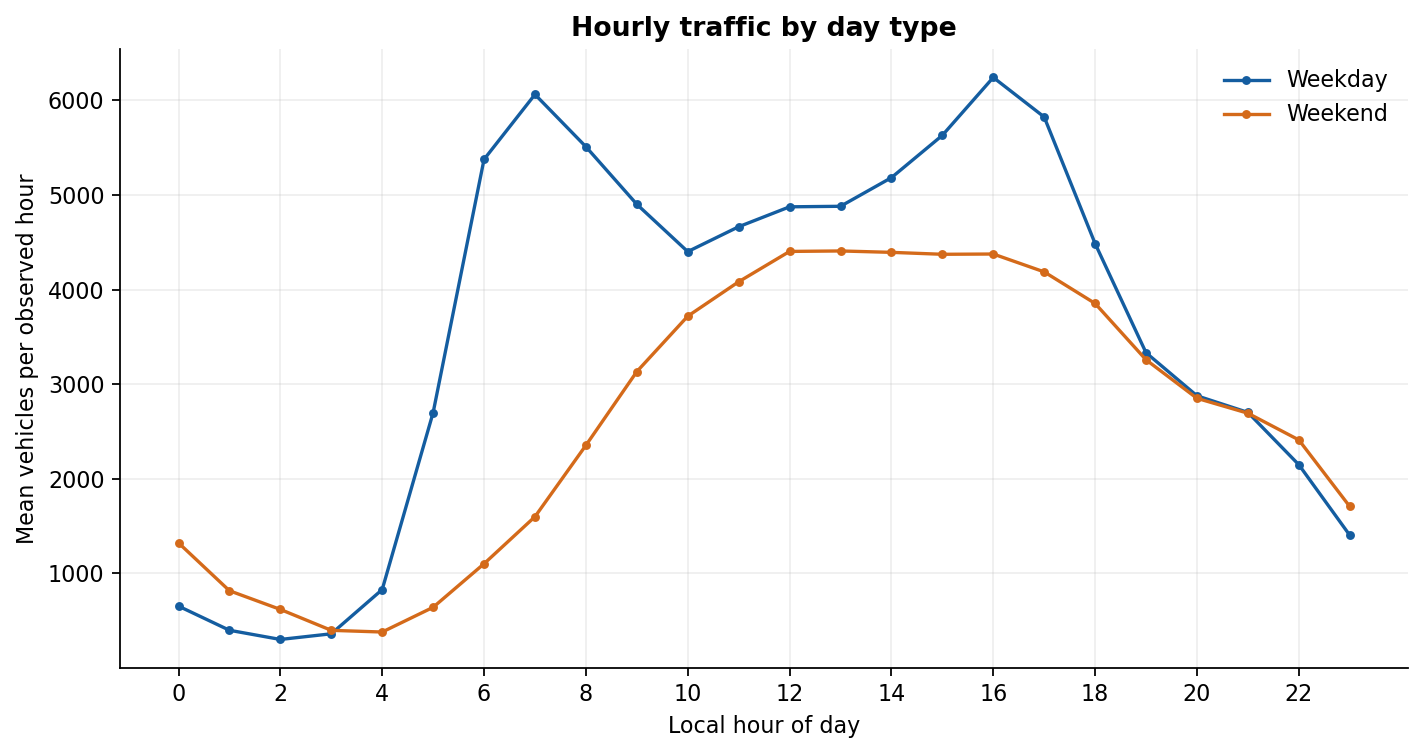

mean  count
is_weekend hour                    
0          0      655.215559   1234
           1      400.186161   1214
           2      303.099343   1218
           3      362.868003   1197
1          0     1323.411043    489
           1      817.800403    496
           2      620.313152    479
           3      399.438559    472

In [13]:
display(Image(filename=str(FIGURES / "01_hourly_day_type.png")))
display(features.groupby(["is_weekend", "hour"]).traffic_volume.agg(["mean", "count"]).groupby(level=0).head(4))

### Figure 2 Weather and traffic

Smoke has the highest mean, 4,443, from only two hours; Squall has the lowest, 2,061.75, from four. Their difference is 2,381.25. Orange flags fewer than 30 observations as a display convention, not a significance threshold. Weather averages depend on the selection rule and do not establish causal effects.

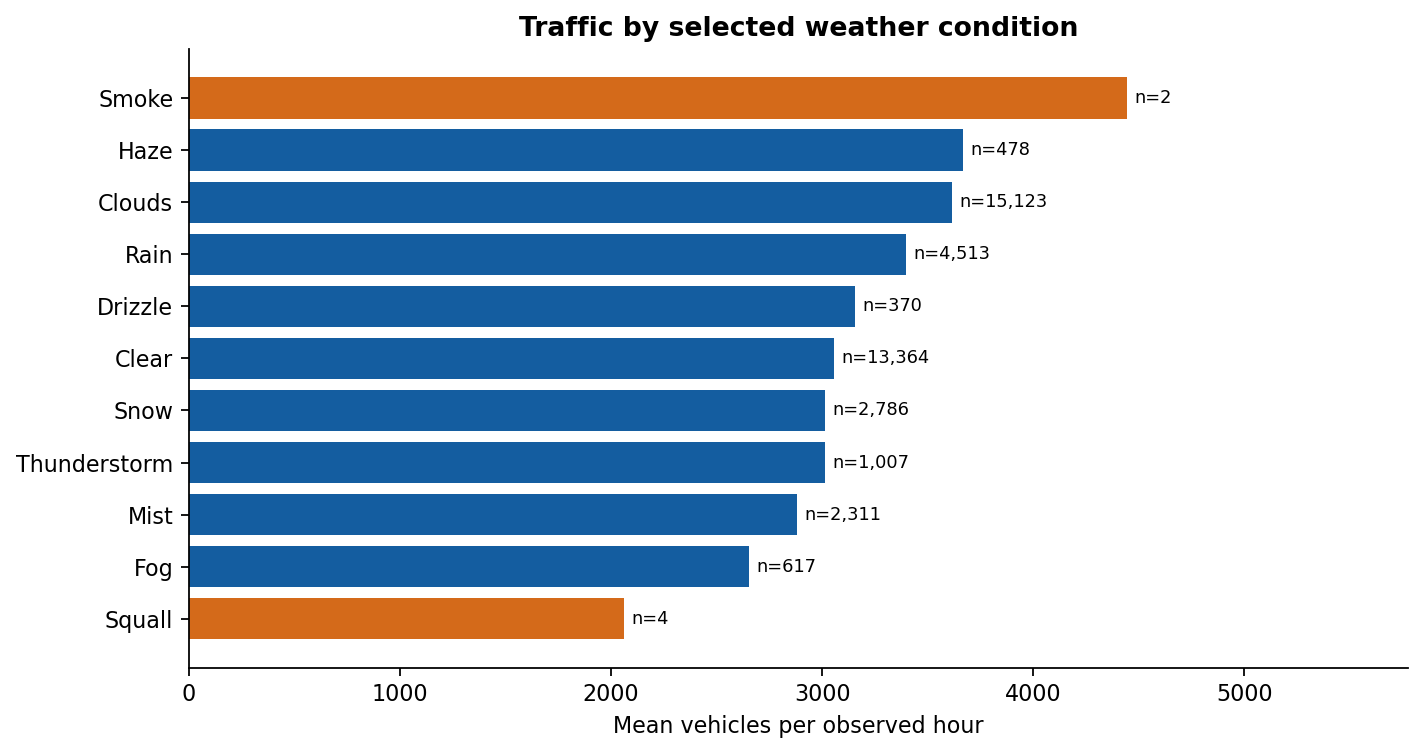

,mean,count
weather_main,,
Smoke,4443.000000,2
Haze,3668.832636,478
Clouds,3616.709780,15123
Rain,3398.148238,4513
Drizzle,3153.494595,370
Clear,3055.164996,13364
Snow,3011.916368,2786
Thunderstorm,3011.111221,1007
Mist,2881.515361,2311


In [14]:
display(Image(filename=str(FIGURES / "02_weather_traffic.png")))
display(features.groupby("weather_main").traffic_volume.agg(["mean", "count"]).sort_values("mean", ascending=False))

### Figure 3 Temperature and traffic density

Hexagons show how many observations overlap; colours use a logarithmic count scale. Traffic varies widely at similar temperatures. Pearson correlation is approximately 0.13954, a weak positive linear association. Hour, weekday and season can confound it.

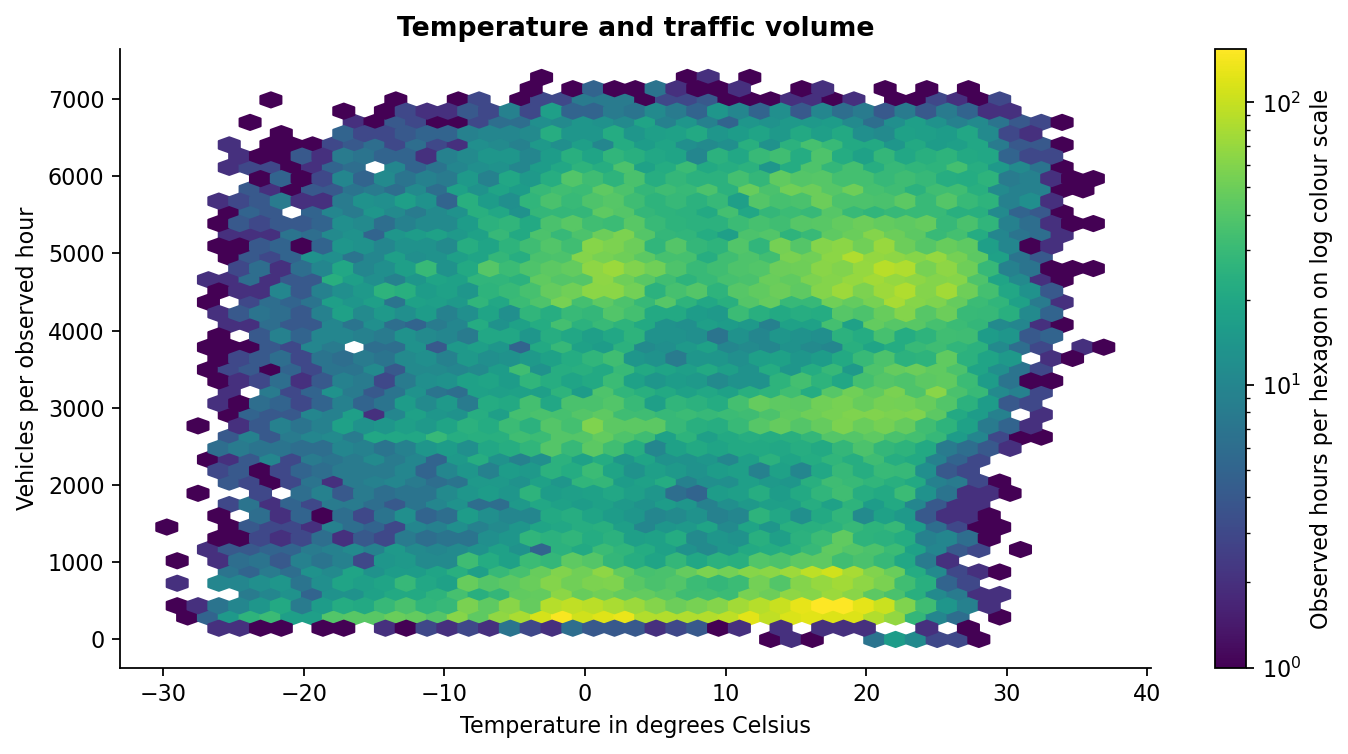

,Statistic,Value
0,Temperature vs traffic Pearson r,0.139536


In [15]:
display(Image(filename=str(FIGURES / "03_temperature_traffic.png")))
display(pd.DataFrame({"Statistic": ["Temperature vs traffic Pearson r"], "Value": [features.temp_c.corr(features.traffic_volume)]}))

### Figure 4 Traffic distribution

The mean is 3,290.65, median 3,427 and sample SD 1,984.77 vehicles per observed hour. Broad variation makes a single average insufficient for every hour. Median/Q3 lines connect the plot to the category definitions. Ties mean the quartile groups need not contain exactly equal numbers of rows.

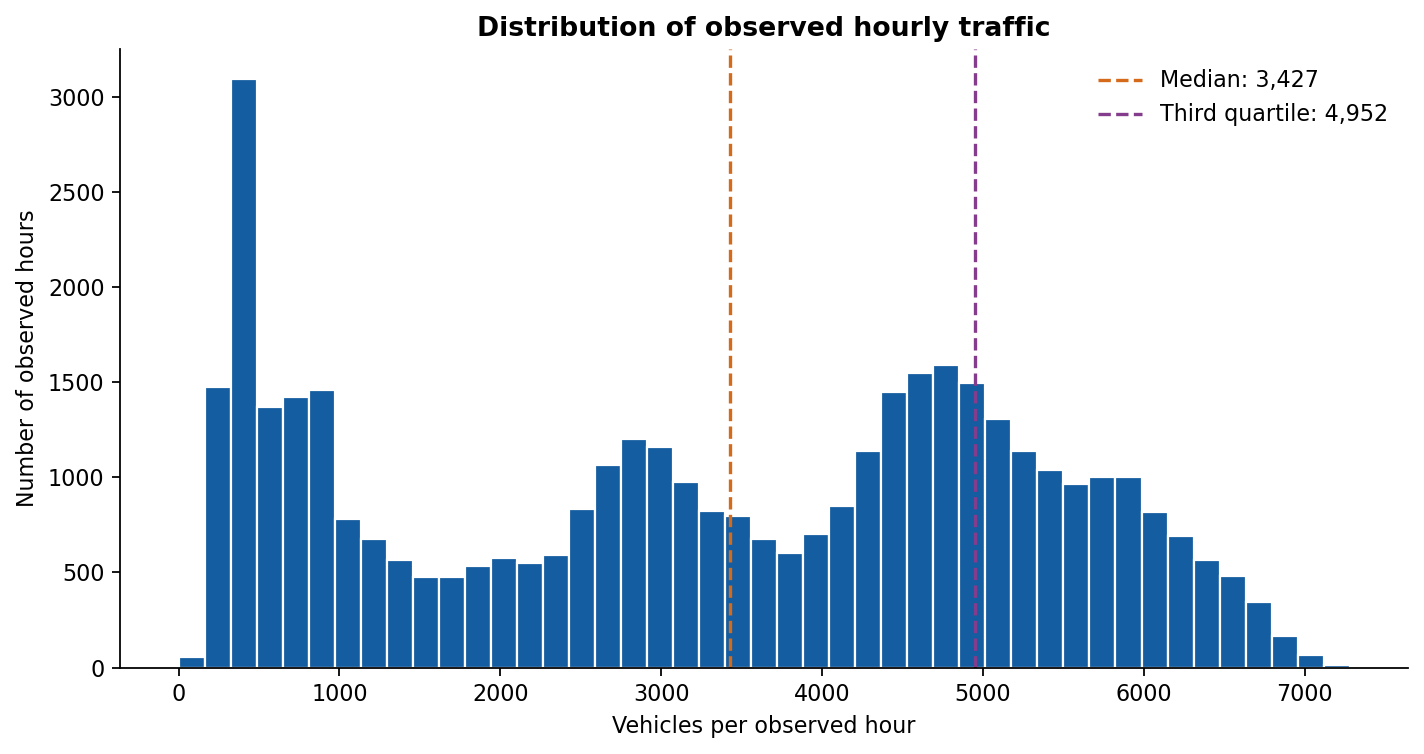

,Traffic volume
count,40575.000000
mean,3290.650474
std,1984.772909
min,0.000000
25%,1248.500000
50%,3427.000000
75%,4952.000000
max,7280.000000


In [16]:
display(Image(filename=str(FIGURES / "04_traffic_distribution.png")))
display(features.traffic_volume.describe().to_frame("Traffic volume"))

## 9 Run the mini CLI application from Jupyter

The real CLI is `app.py`. Using `subprocess.run` with a list of arguments runs it in a separate Python process, just like a terminal, without shell quoting problems. Each command logs its name and arguments. The helper below displays actual command answers; internal progress still uses loggers.

Global options such as `--data` and `--log` precede the command. The examples query the data just generated by this notebook.

In [17]:
cli_evidence = []
def run_cli(arguments, expected_returncode=0):
    command = [sys.executable, str(PROJECT / "app.py"), "--data", str(PROCESSED / "traffic_features.csv"),
               "--log", str(OUT / "app.log"), *arguments]
    result = subprocess.run(command, cwd=PROJECT, capture_output=True, text=True)
    logger.info("CLI demonstration %s returned %d", arguments, result.returncode)
    assert result.returncode == expected_returncode, result.stderr
    cli_evidence.append({"arguments": arguments, "exit_code": result.returncode, "stdout": result.stdout, "stderr": result.stderr})
    if result.stdout:
        display(Code(result.stdout, language="text"))
    if expected_returncode != 0:
        assert "Traceback" not in result.stderr
        display(Code(result.stderr, language="text"))
    return result

run_cli(["--help"]);

2026-10-28 16:43:00,520 | INFO | __main__ | CLI demonstration ['--help'] returned 0


usage: app.py [-h] [--data DATA] [--log LOG] [--debug]
              {at,high,compare,travel} ...

Query observed traffic hours; no route or live travel-time predictions

positional arguments:
  {at,high,compare,travel}
    at                  Find an exact recorded local hour
    high                List observed hours above a traffic threshold
    compare             Compare observed weekday and weekend traffic
    travel              Rank historically quieter hours inside your permitted
                        window

options:
  -h, --help            show this help message and exit
  --data DATA
  --log LOG
  --debug

### Command 1 Look up an exact hour
The timestamp must identify an exact local hour. Missing observations are explicitly reported instead of fabricated.

In [18]:
run_cli(["at", "2017-06-15 08:00:00"]);

2026-10-28 16:43:03,111 | INFO | __main__ | CLI demonstration ['at', '2017-06-15 08:00:00'] returned 0


date_time  traffic_volume weather_main  temp_c congestion_category  high_risk
2017-06-15 08:00:00            5945        Clear   20.46              Severe          0

### Command 2 List high-traffic observations
This uses Part 1's >5,500 threshold and returns the top five matching hours. It is separate from the proxy label.

In [19]:
run_cli(["high", "--threshold", "5500", "--limit", "5"]);

2026-10-28 16:43:05,445 | INFO | __main__ | CLI demonstration ['high', '--threshold', '5500', '--limit', '5'] returned 0


6,107 observed hours exceed 5500 vehicles/hour.
          date_time  traffic_volume weather_main
2017-03-09 16:00:00            7280       Clouds
2016-04-21 07:00:00            7260         Rain
2016-04-22 07:00:00            7241        Clear
2013-04-30 07:00:00            7217        Clear
2018-04-12 16:00:00            7213       Clouds

### Command 3 Compare weekdays with weekends
The answer includes both average traffic and the number of observed hours.

In [20]:
run_cli(["compare"]);

2026-10-28 16:43:08,157 | INFO | __main__ | CLI demonstration ['compare'] returned 0


mean  count
is_weekend                
Weekday    3,557.44  28979
Weekend    2,623.93  11596

### Command 4 Rank historically quieter hours in a permitted window
The window below includes 07:00 through 10:00 on weekdays. Lower historical traffic is not a guarantee of faster or safer travel.

In [21]:
run_cli(["travel", "--day-type", "weekday", "--start", "7", "--end", "10"]);

2026-10-28 16:43:10,639 | INFO | __main__ | CLI demonstration ['travel', '--day-type', 'weekday', '--start', '7', '--end', '10'] returned 0


mean  count
hour                
10   4,400.51   1216
9    4,900.60   1170
8    5,508.90   1199
7    6,061.16   1188
Historical average volumes only. Lower volume does not guarantee shorter or safer journeys.

### Demonstrate graceful invalid-input handling
A malformed date is expected to return exit code 2 and a clear ERROR without a traceback. The notebook catches this expected result so Run All still completes successfully.

In [22]:
run_cli(["at", "not-a-date"], expected_returncode=2)
(OUT / "cli_examples.json").write_text(json.dumps(cli_evidence, indent=2), encoding="utf-8")
logger.info("Saved real CLI demonstration outputs")

2026-10-28 16:43:13,294 | INFO | __main__ | CLI demonstration ['at', 'not-a-date'] returned 2


2026-10-28 16:43:12,682 | INFO | __main__ | CLI command=at arguments={'data': 'C:\\Users\\Admin\\Capstone_Part2\\notebook_outputs\\processed\\traffic_features.csv', 'log': 'C:\\Users\\Admin\\Capstone_Part2\\notebook_outputs\\app.log', 'debug': False, 'command': 'at', 'timestamp': 'not-a-date'}
2026-10-28 16:43:13,175 | ERROR | __main__ | Cannot answer command: time data "not-a-date" doesn't match format "%Y-%m-%d %H:%M:%S". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

2026-10-28 16:43:13,302 | INFO | __main__ | Saved real CLI demonstration outputs


## 10 Inspect normal and DEBUG logging

INFO records loading, dimensions, saves and milestones. WARNING records counts and reasons for repairs. ERROR records rejected operations. DEBUG records fitted parameters only when enabled.

The next cell switches DEBUG on briefly to demonstrate the same quartile logging, then restores INFO. It does not change any data. The notebook log legitimately contains expected ERROR and DEBUG demonstrations; the original project's normal `pipeline.log` remains separate.

In [23]:
logging.getLogger().setLevel(logging.DEBUG)
for handler in logging.getLogger().handlers:
    handler.setLevel(logging.DEBUG)
logger.debug("Notebook quartile parameters: %s", metadata["quartiles"])
logging.getLogger().setLevel(logging.INFO)
for handler in logging.getLogger().handlers:
    handler.setLevel(logging.INFO)

for handler in logging.getLogger().handlers:
    handler.flush()
log_text = (OUT / "pipeline.log").read_text(encoding="utf-8")
assert "| DEBUG |" in log_text and "| INFO |" in log_text and "| WARNING |" in log_text and "| ERROR |" in log_text
display(Code("\n".join(log_text.splitlines()[-12:]), language="text"))

2026-10-28 16:43:13,400 | DEBUG | __main__ | Notebook quartile parameters: {'q1': 1248.5, 'q2': 3427.0, 'q3': 4952.0}


2026-10-28 16:42:54,579 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\01_hourly_day_type.png
2026-10-28 16:42:55,245 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\02_weather_traffic.png
2026-10-28 16:42:56,763 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\03_temperature_traffic.png
2026-10-28 16:42:57,524 | INFO | visualizations | Figure saved: C:\Users\Admin\Capstone_Part2\notebook_outputs\figures\04_traffic_distribution.png
2026-10-28 16:43:00,520 | INFO | __main__ | CLI demonstration ['--help'] returned 0
2026-10-28 16:43:03,111 | INFO | __main__ | CLI demonstration ['at', '2017-06-15 08:00:00'] returned 0
2026-10-28 16:43:05,445 | INFO | __main__ | CLI demonstration ['high', '--threshold', '5500', '--limit', '5'] returned 0
2026-10-28 16:43:08,157 | INFO | __main__ | CLI demonstration ['compare'] returned 0
2026-10-28 16:43:10,639 | INFO | __main__ | CLI demonstration ['travel', '--day-type', 'weekday', '--start', '7', '--end', '10'] returned 0
2026-10-28 16:43:13,294 | INFO | __main__ | CLI demonstration ['at', 'not-a-date'] returned 2
2026-10-28 16:43:13,302 | INFO | __main__ | Saved real CLI demonstration outputs
2026-10-28 16:43:13,400 | DEBUG | __main__ | Notebook quartile parameters: {'q1': 1248.5, 'q2': 3427.0, 'q3': 4952.0}

## 11 Verify the end-to-end script and tests

The notebook calls the existing pipeline entry point in a separate process to check the runnable script as well as the individual functions. It saves its own integration outputs. Then it runs the ten project behaviour tests, including schema failure, both proxy counts, target boundaries, scaling and CLI error handling.

In [24]:
integration_dir = OUT / "integration"
command = [sys.executable, str(PROJECT / "pipeline.py"), "--input", str(RAW_PATH),
           "--output-dir", str(integration_dir / "processed"), "--figures-dir", str(integration_dir / "figures"),
           "--log", str(integration_dir / "pipeline.log")]
result = subprocess.run(command, cwd=PROJECT, capture_output=True, text=True)
assert result.returncode == 0, result.stderr
integration_summary = json.loads((integration_dir / "processed/summary.json").read_text())
assert integration_summary["high_risk_hours"] == 3133
logger.info("Standalone pipeline integration run passed")
display(pd.DataFrame({"Check": ["Standalone pipeline exit code", "Integrated observed hours", "Integrated proxy positives"],
                      "Result": [result.returncode, integration_summary["hours"], integration_summary["high_risk_hours"]]}))

2026-10-28 16:43:20,817 | INFO | __main__ | Standalone pipeline integration run passed


,Check,Result
0,Standalone pipeline exit code,0
1,Integrated observed hours,40575
2,Integrated proxy positives,3133


In [25]:
tests = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                       cwd=PROJECT, capture_output=True, text=True)
(OUT / "test_results.txt").write_text(tests.stdout + tests.stderr, encoding="utf-8")
display(Code(tests.stdout + tests.stderr, language="text"))
assert tests.returncode == 0, "Project tests failed; review notebook_outputs/test_results.txt"
logger.info("All ten project tests passed")

1730 rows affected: standardise weather_description
17 rows affected: remove exact duplicate rows
10 rows affected: temp outside [150, 350] or missing; mark for monthly median imputation
4 rows imputed: temp month=1 median=264.2500
6 rows imputed: temp month=2 median=264.1500
1 rows affected: rain_1h outside [0, 9000] or missing; mark for monthly median imputation
1 rows imputed: rain_1h month=7 median=0.0000
1348 rows affected: propagate holiday marker within observed calendar date
7612 rows affected: collapse repeated hours using severe weather selection
test_cli_commands_and_errors (test_project.ProjectTests.test_cli_commands_and_errors) ... ok
test_collapse_sensitivity (test_project.ProjectTests.test_collapse_sensitivity) ... 1730 rows affected: standardise weather_description
17 rows affected: remove exact duplicate rows
10 rows affected: temp outside [150, 350] or missing; mark for monthly median imputation
4 rows imputed: temp month=1 median=264.2500
6 rows imputed: temp month=2 median=264.1500
1 rows affected: rain_1h outside [0, 9000] or missing; mark for monthly median imputation
1 rows imputed: rain_1h month=7 median=0.0000
1348 rows affected: propagate holiday marker within observed calendar date
7612 rows affected: collapse repeated hours using first weather selection
ok
test_debug_hidden_in_normal_run (test_project.ProjectTests.test_debug_hidden_in_normal_run) ... ok
test_hour_cycle_wraps (test_project.ProjectTests.test_hour_cycle_wraps) ... ok
test_hourly_grain_and_counts (test_project.ProjectTests.test_hourly_grain_and_counts) ... ok
test_invalid_values_and_missing_dates (test_project.ProjectTests.test_invalid_values_and_missing_dates) ... ok
test_missing_file_logs_error_and_fails_gracefully (test_project.ProjectTests.test_missing_file_logs_error_and_fails_gracefully) ... ok
test_scaling_fitted_only_on_reference_period (test_project.ProjectTests.test_scaling_fitted_only_on_reference_period) ... ok
test_schema_rejects_before_cleaning (test_project.ProjectTests.test_schema_rejects_before_cleaning) ... ok
test_targets_and_boundaries (test_project.ProjectTests.test_targets_and_boundaries) ... ok

----------------------------------------------------------------------
Ran 10 tests in 22.195s

OK

2026-10-28 16:43:44,748 | INFO | __main__ | All ten project tests passed


## 12 Review local Git history and submission status

The project retains genuine incremental local commits. The following cell is read-only. No GitHub publication is performed. Creating an online repository remains an account step if your lecturer requires a link; the README contains the commands.

A notebook supplements the mandatory Python scripts rather than replacing them. Submit the full project folder or repository, including scripts, figures, sample logs, README and the short report.

In [26]:
try:
    git = subprocess.run(["git", "log", "--oneline", "-8"], cwd=PROJECT, capture_output=True, text=True)
    if git.returncode == 0:
        display(Code(git.stdout, language="text"))
    else:
        logger.warning("Git history unavailable in this extracted copy: %s", git.stderr.strip())
        display(Markdown("Git history could not be read. Ensure the ZIP was extracted with its `.git` folder."))
except FileNotFoundError:
    logger.warning("Git executable is not installed in this environment")
    display(Markdown("Git is not installed; the analysis can still run. Install Git to inspect local commits."))

3c87139 Add executed Jupyter walkthrough with charts CLI examples and integration verification
ebdc318 Record final successful production run in clean sample log
1d696f4 Task 5 verify pipeline and document reproducibility with real outputs and reports
84e903d Task 4 implement four CLI queries with logged inputs and friendly errors
c6d6c7e Task 3 add four traffic visualisations and numerical summary exports
ecf629c Task 2 engineer cyclical weather and scaled features with documented targets
808c3a6 Task 1 build validated hourly pipeline with auditable cleaning and logging

## 13 Findings, limitations and next steps

- The pipeline yields **40,575 unique observed hours** and a **44-column feature table**.
- The documented weather rule yields **3,133 proxy positives (7.7215%)**; first-row selection yields **2,964 (7.3050%)**. State the rule alongside the result.
- Mean hourly traffic is **3,290.65** and SD **1,984.77**. Weekday commuter peaks differ from weekend midday patterns.
- Temperature has a weak positive linear association with traffic. Rare weather means are unstable and associations are not causal estimates.
- Missing hours and partial-year coverage mean annual sums are not complete-year demand. Traffic volume alone does not establish delay, speed, emissions or accident likelihood.
- For Part 3, split chronologically **before** fitting preprocessing and label thresholds for strict future evaluation. Full-hourly descriptive quartiles here reproduce the assignment convention. Never feed `traffic_volume` or its derived labels into the proxy classifier; use `model_predictor_columns` from the metadata.
- The proxy is uncommon: an always-negative classifier would obtain high accuracy while finding no positives. Later classification evaluation should include precision, recall, F1 and PR-AUC. No classifier is trained in Part 2.

**Data credit:** Hogue, J. (2019), *Metro Interstate Traffic Volume*, UCI Machine Learning Repository, https://doi.org/10.24432/C5X60B, CC BY 4.0. The original CSV is bundled. No online data access is required when rerunning this notebook.

In [27]:
checklist = pd.DataFrame({
    "Deliverable check": ["Cleaned unique hours", "Engineered columns", "Severity proxy positives", "First-row proxy positives", "Matplotlib figures", "Four CLI query commands", "Behaviour tests", "Standalone pipeline"],
    "Result": [len(hourly), features.shape[1], int(features.high_risk.sum()), first_count,
               len(list(FIGURES.glob("*.png"))), 4, "10 passed", "Passed"]})
display(checklist)
(OUT / "notebook_summary.json").write_text(json.dumps({"hours": len(hourly), "columns": features.shape[1], "high_risk": int(features.high_risk.sum()), "first_row_high_risk": first_count, "tests_passed": True}, indent=2), encoding="utf-8")
logger.info("Notebook completed successfully")

,Deliverable check,Result
0,Cleaned unique hours,40575
1,Engineered columns,44
2,Severity proxy positives,3133
3,First-row proxy positives,2964
4,Matplotlib figures,4
5,Four CLI query commands,4
6,Behaviour tests,10 passed
7,Standalone pipeline,Passed


2026-10-28 16:43:45,238 | INFO | __main__ | Notebook completed successfully
